# Evaluation

Run `modeling.ipynb` first, since it writes the code used here.

In [1]:
import os
from pathlib import Path

# The code reads data/... relative to the repo root, and notebooks start in notebooks/.
if Path.cwd().name == "notebooks":
    os.chdir("..")
print(Path.cwd())

/home/indigo/spotterAssessment


In [2]:
import sys

import numpy as np
import pandas as pd
from IPython.display import Image

from spotterassessment import predict
from spotterassessment.backtest import (FORWARD_FOLDS, TREE_FEATURES, baseline_predict, evaluate,
                                        make_splits, ridge_predict, score, summarize, tree_predict)
from spotterassessment.features import add_features, bad_rate_mask, daily_market, load
from spotterassessment.model import FreightRateModel

pd.set_option("display.width", 220, "display.max_columns", 20)
raw, future = load("train_test"), load("validation")
market = daily_market(raw, future)
fill = raw["weight"].abs().median()
splits = list(make_splits(raw, market))
with_quote = lambda tr, te: tree_predict(tr, te, TREE_FEATURES + ["quote_signal"])

# The final model, trained on all clean labeled rows
all_train = add_features(raw[~bad_rate_mask(raw)], market, fill)
final = FreightRateModel().fit(all_train)
validation_rows = add_features(future, market, fill)
validation_pred = final.predict(validation_rows)

## Validation

Each test window is two months, like Nov-Dec, and training always ends before testing starts. Leave-Aug is an extra check and isn't included in the averages, because it trains on later months too.

### Random split vs time

In [3]:
# Random split: 80% of rows train, 20% test
fill = raw["weight"].abs().median()
full = add_features(raw.assign(bad_rate=bad_rate_mask(raw)), market, fill)
in_train = np.random.RandomState(0).rand(len(full)) < 0.8
random_train, random_test = full[in_train & ~full["bad_rate"]], full[~in_train]

# Leave-August-out
_, august_train, august_test = next(split for split in splits if split[0] == "Leave-Aug")

rows = []
for name, predict in {"Without quote_signal": tree_predict, "With quote_signal": with_quote}.items():
    rows.append({
        "tree model": name,
        "random split MAPE": score(random_test, predict(random_train, random_test))["mape"],
        "leave-August-out MAPE": score(august_test, predict(august_train, august_test))["mape"],
    })
print(pd.DataFrame(rows).round(2).to_string(index=False))

          tree model  random split MAPE  leave-August-out MAPE
Without quote_signal               2.98                   2.06
   With quote_signal               2.03                   4.53


`quote_signal` looks better on a random split (2.03% vs 2.98%), but much worse on August (4.53% vs 2.06%). A random split would have led me to the wrong choice.

### Folds

In [4]:
for name, tr, te in splits:
    print(f"{name:10} train {tr.date.min().date()} to {tr.date.max().date()} ({len(tr):,} rows)"
          f" | test {te.date.min().date()} to {te.date.max().date()} ({len(te):,} rows)")
    if name in FORWARD_FOLDS:
        assert tr.date.max() < te.date.min(), "training must end before testing starts"

Mar-Apr    train 2025-01-01 to 2025-02-28 (9,117 rows) | test 2025-03-01 to 2025-04-30 (9,855 rows)
May-Jun    train 2025-01-01 to 2025-04-30 (18,835 rows) | test 2025-05-01 to 2025-06-30 (9,696 rows)
Jul-Aug    train 2025-01-01 to 2025-06-30 (28,406 rows) | test 2025-07-01 to 2025-08-31 (9,671 rows)
Sep-Oct    train 2025-01-01 to 2025-08-31 (37,944 rows) | test 2025-09-01 to 2025-10-31 (9,523 rows)
Leave-Aug  train 2025-01-01 to 2025-10-31 (42,632 rows) | test 2025-08-01 to 2025-08-31 (4,759 rows)


### Metrics

Spotter's metric isn't known, so I track MAPE, MAE, RMSE, and bias.

In [5]:
print(evaluate({"structural ridge": ridge_predict}, splits).round(2).to_string(index=False))

           model      fold  mape   mae  rmse  mae_all  rmse_all  bias
structural ridge   Mar-Apr  2.21 54.98 84.13    97.45    533.64 -1.72
structural ridge   May-Jun  2.07 51.55 79.17   105.31    633.65 -1.12
structural ridge   Jul-Aug  3.00 69.93 93.75   121.62    620.45  2.87
structural ridge   Sep-Oct  2.24 52.18 76.54   108.06    634.05 -1.81
structural ridge Leave-Aug  1.90 44.55 63.82    94.61    612.75  1.54


## Results

In [6]:
results = evaluate({"median baseline": baseline_predict, "first LightGBM": tree_predict,
                    "structural ridge": ridge_predict}, splits)
print(summarize(results).to_string())

                  mape     mae    rmse  mae_all  rmse_all  bias  worst_mape  Mar-Apr  May-Jun  Jul-Aug  Sep-Oct  Leave-Aug
model                                                                                                                     
median baseline   4.73  108.26  147.06   158.63    622.66 -2.89        6.17     5.26     6.17     3.80     3.68       3.71
first LightGBM    3.76   91.59  125.14   142.04    617.67 -2.90        5.87     4.67     5.87     2.42     2.08       2.06
structural ridge  2.38   57.16   83.40   108.11    605.45 -0.45        3.00     2.21     2.07     3.00     2.24       1.90


Ridge averages 2.38% with a worst fold of 3.00%, against 3.76% and 5.87% for LightGBM. LightGBM does beat it on Jul-Aug and Sep-Oct.

In [7]:
# How close to perfect? The same ridge on the random split from above
print("ridge on a random split:", round(score(random_test, ridge_predict(random_train, random_test))["mape"], 2))

ridge on a random split: 1.66


On a random split the same ridge gets 1.66%, which is roughly the noise floor.

## Unseen cities

In [8]:
# Eight random cities held out, 10 repeats, tested on Sep-Oct
cities = sorted(set(raw["pickup"]) | set(raw["delivery"]))
rng = np.random.RandomState(1)
rows = []
for repeat in range(10):
    held = set(rng.choice(cities, 8, replace=False))
    touches = full["pickup"].isin(held) | full["delivery"].isin(held)
    tr = full[(full["date"] <= "2025-08-31") & ~full["bad_rate"] & ~touches]
    te = full[(full["date"] > "2025-08-31") & touches]
    rows.append({"model": "ridge", **score(te, ridge_predict(tr, te))})
    rows.append({"model": "tree", **score(te, tree_predict(tr, te))})
print(pd.DataFrame(rows).groupby("model")[["mape", "mae", "bias"]].agg(["mean", "std"]).round(2).to_string())

       mape          mae         bias      
       mean   std   mean    std  mean   std
model                                      
ridge  2.27  0.05  53.83   3.97 -1.86  0.08
tree   2.89  0.23  68.74  11.68 -0.55  0.66


In [9]:
# Cities at the edge of the map held out, tested on Sep-Oct
latitude = full.groupby("pickup")["pickup_lat"].first().sort_values()
longitude = full.groupby("pickup")["pickup_lon"].first().sort_values()
groups = {"south": latitude.index[:3], "north": latitude.index[-2:], "west": longitude.index[:2], "east": longitude.index[-2:]}
for name, members in groups.items():
    touches = full["pickup"].isin(members) | full["delivery"].isin(members)
    tr = full[(full["date"] <= "2025-08-31") & ~full["bad_rate"] & ~touches]
    te = full[(full["date"] > "2025-08-31") & touches]
    print(name, list(members), "ridge", round(score(te, ridge_predict(tr, te))["mape"], 2),
          "tree", round(score(te, tree_predict(tr, te))["mape"], 2))

south ['Tampa', 'Los Angeles', 'Corpus Christi'] ridge 2.03 tree 2.62
north ['Albany', 'Green Bay'] ridge 1.95 tree 2.59
west ['San Francisco', 'Fresno'] ridge 2.28 tree 4.57
east ['Boston', 'Providence'] ridge 2.65 tree 4.52


In [10]:
# Laredo, the city below the training latitude range
per_mile = validation_pred / validation_rows["distance"]
unseen = {"Allentown", "Charlotte", "Chicago", "Jackson", "Knoxville", "Laredo", "Norfolk", "San Diego"}
laredo = (validation_rows["pickup"] == "Laredo") | (validation_rows["delivery"] == "Laredo")
seen = ~(validation_rows["pickup"].isin(unseen) | validation_rows["delivery"].isin(unseen))
print("Laredo $/mile:", round(per_mile[laredo].median(), 2), "| rows touching only seen cities:", round(per_mile[seen].median(), 2))

Laredo $/mile: 2.15 | rows touching only seen cities: 2.16


Ridge holds up better than LightGBM when cities are held out. Laredo's predictions look reasonable.

## Choosing the final variant

In [11]:
def variant(no_market=False, no_time=False, extrapolate=False):
    def fit_predict(tr, te):
        tr2, te2 = tr.copy(), te.copy()
        if no_market:
            tr2["market"], te2["market"] = 0.0, 0.0
        if no_time:
            tr2["months_elapsed"], te2["months_elapsed"] = 0.0, 0.0
        model = FreightRateModel().fit(tr2)
        if extrapolate:
            model.last_time = np.inf
        return model.predict(te2)
    return fit_predict

print(summarize(evaluate({
    "final: market + frozen trend": variant(),
    "no market, no time": variant(no_market=True, no_time=True),
    "market only": variant(no_time=True),
    "market + extrapolated trend": variant(extrapolate=True),
}, splits)).to_string())

                              mape    mae    rmse  mae_all  rmse_all  bias  worst_mape  Mar-Apr  May-Jun  Jul-Aug  Sep-Oct  Leave-Aug
model                                                                                                                                
final: market + frozen trend  2.38  57.16   83.40   108.11    605.45 -0.45        3.00     2.21     2.07     3.00     2.24       1.90
no market, no time            3.56  87.37  118.05   137.93    616.59 -2.90        5.67     4.47     5.67     2.22     1.86       1.86
market only                   2.77  66.46   93.67   117.31    610.14 -2.33        4.36     2.34     2.26     2.11     4.36       1.42
market + extrapolated trend   2.49  59.01   84.30   109.91    604.61  0.46        4.35     1.96     1.68     4.35     1.96       1.90


The version with no market or time terms wins Sep-Oct (1.86% vs 2.24%), and that's the fold most like Nov-Dec. I still chose market + frozen trend, because its worst fold is 3.00% vs 5.67%, and the simpler version can't show a weekly pattern. This is a judgment call, and it could go the other way if rates drop back.

In [12]:
# After fitting, how far off is the final model in each training month?
residual = np.log(all_train["posted_rate"]) - np.log(final.predict(all_train))
print(residual.groupby(all_train["date"].dt.month).mean().round(3).to_dict())

# How much is at stake on validation?
no_time_pred = variant(no_market=True, no_time=True)(all_train, validation_rows)
tree_pred = tree_predict(all_train, validation_rows)
print("final / no market, no time, median:", round(np.median(validation_pred / no_time_pred), 3))
print("final / LightGBM, median:", round(np.median(validation_pred / tree_pred), 3))

{1: -0.003, 2: -0.005, 3: 0.014, 4: -0.007, 5: -0.004, 6: 0.016, 7: -0.007, 8: -0.012, 9: 0.009, 10: -0.003}
final / no market, no time, median: 1.009
final / LightGBM, median: 1.009


## Other checks

In [13]:
# Ridge penalty
print(summarize(evaluate({f"alpha={a}": (lambda a: lambda tr, te: FreightRateModel(alpha=a).fit(tr).predict(te))(a)
                          for a in (0.001, 0.01, 0.1, 1.0, 10.0)}, splits)).to_string())

             mape    mae    rmse  mae_all  rmse_all  bias  worst_mape  Mar-Apr  May-Jun  Jul-Aug  Sep-Oct  Leave-Aug
model                                                                                                               
alpha=0.001  2.38  57.15   83.37   108.10    605.46 -0.45        3.00     2.21     2.07     3.00     2.24       1.90
alpha=0.01   2.38  57.16   83.40   108.11    605.45 -0.45        3.00     2.21     2.07     3.00     2.24       1.90
alpha=0.1    2.40  57.58   84.17   108.52    605.48 -0.44        3.00     2.25     2.09     3.00     2.25       1.91
alpha=1.0    2.48  59.27   87.07   110.18    605.86 -0.44        3.05     2.37     2.20     3.05     2.31       1.98
alpha=10.0   2.73  65.03  101.07   115.88    608.85 -0.46        3.20     2.89     2.39     3.20     2.43       2.10


In [14]:
# Corruption threshold
rows = []
for low, high in [(0, 1e9), (0.4, 2.5), (0.5, 2.0), (0.6, 1.6), (0.7, 1.4), (0.8, 1.25)]:
    rows.append(evaluate({f"keep {low}-{high}": ridge_predict}, list(make_splits(raw, market, low, high))))
print(summarize(pd.concat(rows)).to_string())

                     mape    mae   rmse  mae_all  rmse_all  bias  worst_mape  Mar-Apr  May-Jun  Jul-Aug  Sep-Oct  Leave-Aug
model                                                                                                                      
keep 0-1000000000.0  2.63  63.50  92.45   114.34    606.65 -0.45        3.41     2.61     2.31     3.41     2.20       1.97
keep 0.4-2.5         2.38  57.18  83.54   108.13    605.47 -0.50        2.93     2.26     2.09     2.93     2.23       1.92
keep 0.5-2.0         2.38  57.16  83.40   108.11    605.45 -0.45        3.00     2.21     2.07     3.00     2.24       1.90
keep 0.6-1.6         2.38  57.16  83.40   108.11    605.45 -0.45        3.00     2.21     2.07     3.00     2.24       1.90
keep 0.7-1.4         2.38  57.16  83.40   108.11    605.45 -0.45        3.00     2.21     2.07     3.00     2.24       1.90
keep 0.8-1.25        2.38  57.15  83.38   108.10    605.45 -0.45        3.00     2.21     2.07     3.00     2.24       1.90


The ridge penalty barely matters below 0.1. Filtering corrupted rows helps (2.38% vs 2.63%), but the exact threshold doesn't.

## Final predictions

In [16]:
from spotterassessment.predict import main as write_predictions

write_predictions()

market effect 0.1420, monthly trend 0.0063


In [17]:
!{sys.executable} score.py --predictions validation_predictions.csv --december-predictions data/december_chart_inputs.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


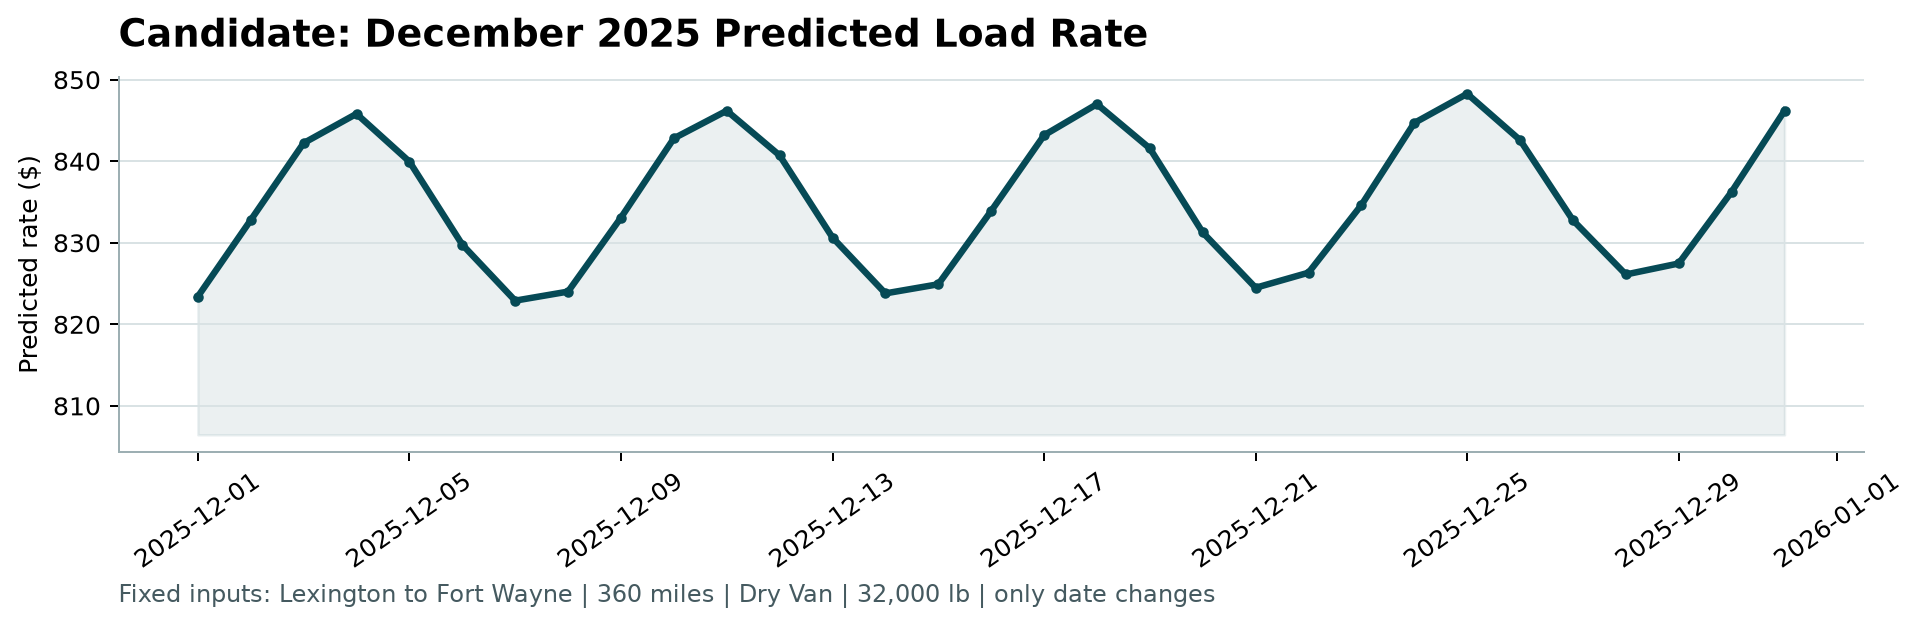

In [18]:
Image("scorer_results/candidate_december.png")